In [2]:

import pandas as pd
import numpy as np

from pathlib import Path

# Find the main project folder
repo_root = Path.cwd()

while repo_root.name != "GroundWatch" and repo_root.parent != repo_root:
    repo_root = repo_root.parent

# Define the dataset path
file_path = (
    repo_root
    / "data"
    / "processed"
    / "groundwater_features.csv"
)

# Check whether the file exists
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

# Load the engineered dataset
model_data = pd.read_csv(file_path)

# Convert dates with mixed formats
model_data["Data Acquisition Time"] = pd.to_datetime(
    model_data["Data Acquisition Time"],
    format="mixed",
    errors="raise"
)

# Display dataset information
print("Dataset loaded successfully!")

print("\nDataset shape:", model_data.shape)

print("\nColumn names:")
print(model_data.columns.tolist())

print("\nDate range:")
print("First observation:", model_data["Data Acquisition Time"].min())
print("Last observation:", model_data["Data Acquisition Time"].max())

print("\nTotal records:", len(model_data))

# Display first five records
model_data.head()


Dataset loaded successfully!

Dataset shape: (113310, 31)

Column names:
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'RL_MSL', 'Data Acquisition Time', 'Groundwater Level Quarterly Manual (meter)', 'Station_ID', 'Source', 'Anomaly_Flag', 'Previous_Groundwater_Level', 'Previous_2_Groundwater_Level', 'Previous_3_Groundwater_Level', 'Month', 'Season', 'Year', 'Rolling_Average_3']

Date range:
First observation: 1996-11-05 06:00:00
Last observation: 2024-08-30 10:00:00

Total records: 113310


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,...,Station_ID,Source,Anomaly_Flag,Previous_Groundwater_Level,Previous_2_Groundwater_Level,Previous_3_Groundwater_Level,Month,Season,Year,Rolling_Average_3
0,39434,Horti,CGWB,29,Karnataka,530,Bijapur,INDI,INDI,Horti,...,Horti_Bijapur_17.11527778_75.7875,Historical,False,12.46,14.50,13.22,11,Post-Monsoon,1996,13.393333
1,83882,Rupnal,CGWB,29,Karnataka,527,Belgaum,CHIKODI,CHIKODI,Rupnal,...,Rupnal_Belgaum_16.475_74.63333333,Historical,False,10.12,9.85,9.04,11,Post-Monsoon,1996,9.670000
2,16729,Bisalahalli,CGWB,29,Karnataka,528,Bellary,BELLARY,BELLARY,Bisalahalli,...,Bisalahalli_Bellary_15.13888889_76.96805556,Historical,False,6.24,6.32,6.75,11,Post-Monsoon,1996,6.436667
3,18572,Chandavar,CGWB,29,Karnataka,550,Uttara Kannada,HONAVAR,HONAVAR,Chandavar,...,Chandavar_Uttara Kannada_14.4_74.47916667,Historical,False,3.50,2.90,6.17,11,Post-Monsoon,1996,4.190000
4,93298,Subramanya1,CGWB,29,Karnataka,534,Dakshin Kannada,SULYA,SULYA,Subramanya,...,Subramanya1_Dakshin Kannada_12.66666667_75.619...,Historical,False,1.98,6.86,6.08,11,Post-Monsoon,1996,4.973333


In [3]:

# Define the target variable
target = "Groundwater Level Quarterly Manual (meter)"

# Define input features
feature_columns = [
    "Previous_Groundwater_Level",
    "Previous_2_Groundwater_Level",
    "Previous_3_Groundwater_Level",
    "Rolling_Average_3",
    "Month",
    "Year"
]

# Separate input features and target
X = model_data[feature_columns]
y = model_data[target]

# Display information
print("Input features:")
print(feature_columns)

print("\nTarget variable:")
print(target)

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in input features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())


Input features:
['Previous_Groundwater_Level', 'Previous_2_Groundwater_Level', 'Previous_3_Groundwater_Level', 'Rolling_Average_3', 'Month', 'Year']

Target variable:
Groundwater Level Quarterly Manual (meter)

Input shape: (113310, 6)
Target shape: (113310,)

Missing values in input features:
Previous_Groundwater_Level      0
Previous_2_Groundwater_Level    0
Previous_3_Groundwater_Level    0
Rolling_Average_3               0
Month                           0
Year                            0
dtype: int64

Missing values in target:
0


In [4]:

# Calculate the chronological split point
split_index = int(len(model_data) * 0.80)

# Split input features
X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

# Split target values
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Display split information
print("Training dataset:")
print("Records:", len(X_train))
print("Start date:", model_data["Data Acquisition Time"].iloc[0])
print("End date:", model_data["Data Acquisition Time"].iloc[split_index - 1])

print("\nTesting dataset:")
print("Records:", len(X_test))
print("Start date:", model_data["Data Acquisition Time"].iloc[split_index])
print("End date:", model_data["Data Acquisition Time"].iloc[-1])

print("\nTotal records:", len(X_train) + len(X_test))


Training dataset:
Records: 90648
Start date: 1996-11-05 06:00:00
End date: 2019-05-28 06:00:00

Testing dataset:
Records: 22662
Start date: 2019-05-28 06:00:00
End date: 2024-08-30 10:00:00

Total records: 113310


In [5]:

# Identify stations in training and testing datasets
train_stations = set(
    model_data.iloc[:split_index]["Station_ID"].unique()
)

test_stations = set(
    model_data.iloc[split_index:]["Station_ID"].unique()
)

# Find common and unseen stations
common_stations = train_stations.intersection(test_stations)
unseen_test_stations = test_stations - train_stations

print("Training stations:", len(train_stations))
print("Testing stations:", len(test_stations))
print("Stations present in both:", len(common_stations))
print("Stations appearing only in testing:", len(unseen_test_stations))


Training stations: 2186
Testing stations: 1897
Stations present in both: 1775
Stations appearing only in testing: 122


In [6]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline predictions using the previous groundwater reading
baseline_predictions = X_test["Previous_Groundwater_Level"]

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL RESULTS")
print("----------------------")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)


BASELINE MODEL RESULTS
----------------------
MAE: 2.4145653518480716
RMSE: 13.368879391497416
R2 Score: -0.5373552512098108


In [7]:

# Create a baseline evaluation DataFrame
baseline_results = pd.DataFrame({
    "Station_ID": model_data.loc[y_test.index, "Station_ID"],
    "Date": model_data.loc[y_test.index, "Data Acquisition Time"],
    "Actual_Level": y_test,
    "Predicted_Level": baseline_predictions,
    "Anomaly_Flag": model_data.loc[y_test.index, "Anomaly_Flag"]
})

# Calculate prediction errors
baseline_results["Absolute_Error"] = abs(
    baseline_results["Actual_Level"] -
    baseline_results["Predicted_Level"]
)

# Display error statistics
print("BASELINE ERROR ANALYSIS")
print("-----------------------")

print("\nAbsolute error statistics:")
print(baseline_results["Absolute_Error"].describe())

print("\nAnomaly flag distribution in test data:")
print(baseline_results["Anomaly_Flag"].value_counts())

print("\n10 observations with the largest prediction errors:")

display(
    baseline_results.nlargest(10, "Absolute_Error")
)


BASELINE ERROR ANALYSIS
-----------------------

Absolute error statistics:
count    22662.000000
mean         2.414565
std         13.149313
min          0.000000
25%          0.550000
50%          1.380000
75%          2.910000
max       1364.200000
Name: Absolute_Error, dtype: float64

Anomaly flag distribution in test data:
Anomaly_Flag
False    22645
True        17
Name: count, dtype: int64

10 observations with the largest prediction errors:


,Station_ID,Date,Actual_Level,Predicted_Level,Anomaly_Flag,Absolute_Error
108931,Turuvekere1_Tumkur_13.16666667_76.66666667,2023-08-25 00:00:00,9.80,1374.00,False,1364.20
108411,Turuvekere1_Tumkur_13.16666667_76.66666667,2023-05-25 00:00:00,1374.00,10.73,True,1363.27
95061,Hampasandra_Kolar_13.66666667_77.425,2020-08-25 00:00:00,1.95,60.00,False,58.05
108255,C.N.Halli1_Tumkur_13.43333333_76.61666667,2023-05-25 00:00:00,1.72,59.35,False,57.63
101315,Mittemari_Kolar_13.70833333_77.86944444,2022-01-30 07:00:00,11.97,68.95,False,56.98
95075,Hebbal2_Bangalore Urban_13.04166667_77.575,2020-08-25 00:00:00,5.85,61.55,False,55.70
107925,R.Nulenur_Chitradurga_14.025_76.125,2023-05-25 00:00:00,57.75,2.24,False,55.51
109790,R.Nulenur_Chitradurga_14.025_76.125,2023-08-25 00:00:00,3.20,57.75,False,54.55
107977,Manvi2_Raichur_16.0_77.03333333,2023-05-25 00:00:00,58.00,3.75,False,54.25
101071,Bangarapet_Kolar_13.025_78.1625,2022-01-30 07:00:00,10.61,59.45,False,48.84


In [8]:

target = "Groundwater Level Quarterly Manual (meter)"

station_id = "Turuvekere1_Tumkur_13.16666667_76.66666667"

# Inspect the station's complete chronological history
station_records = model_data[
    model_data["Station_ID"] == station_id
].sort_values("Data Acquisition Time")

print("TURUVEKERE1 — GROUNDWATER HISTORY")
display(
    station_records[
        [
            "Data Acquisition Time",
            target,
            "Anomaly_Flag",
            "Previous_Groundwater_Level",
            "Previous_2_Groundwater_Level",
            "Previous_3_Groundwater_Level"
        ]
    ].tail(12)
)

# Inspect all flagged observations in the test dataset
print("\nFLAGGED TEST OBSERVATIONS")

display(
    baseline_results[
        baseline_results["Anomaly_Flag"] == True
    ].sort_values("Actual_Level", ascending=False)
)

# Check the maximum groundwater level in the test dataset
print("\nMaximum actual groundwater level in test data:")
print(y_test.max())


TURUVEKERE1 — GROUNDWATER HISTORY


,Data Acquisition Time,Groundwater Level Quarterly Manual (meter),Anomaly_Flag,Previous_Groundwater_Level,Previous_2_Groundwater_Level,Previous_3_Groundwater_Level
95758,2020-11-30 00:00:00,11.59,False,17.84,13.61,19.55
97985,2021-01-10 00:00:00,13.16,False,11.59,17.84,13.61
98645,2021-08-31 06:00:00,15.20,False,13.16,11.59,17.84
100482,2021-11-30 06:00:00,7.87,False,15.20,13.16,11.59
101023,2022-01-30 07:00:00,8.90,False,7.87,15.20,13.16
102539,2022-05-25 00:00:00,11.00,False,8.90,7.87,15.20
103518,2022-08-25 00:00:00,8.87,False,11.00,8.90,7.87
105155,2022-11-05 00:00:00,4.37,False,8.87,11.00,8.90
106674,2023-01-05 00:00:00,10.73,False,4.37,8.87,11.00
108411,2023-05-25 00:00:00,1374.00,True,10.73,4.37,8.87



FLAGGED TEST OBSERVATIONS


,Station_ID,Date,Actual_Level,Predicted_Level,Anomaly_Flag,Absolute_Error
108411,Turuvekere1_Tumkur_13.16666667_76.66666667,2023-05-25 00:00:00,1374.00,10.73,True,1363.27
100560,Gubbi_Tumkur_13.30416667_76.94166667,2022-01-30 07:00:00,-0.01,2.79,True,2.80
113058,Gadag_Gadag_15.425_75.5875,2024-08-25 00:00:00,-0.10,0.10,True,0.20
112999,Begihalli_Bangalore Urban_12.79583333_77.60694444,2024-08-25 00:00:00,-0.13,0.90,True,1.03
92927,Goonadka_Dakshin Kannada_12.51416667_75.49805556,2019-11-28 06:00:00,-0.20,0.40,True,0.60
95050,Sherewad A_Dharwad_15.25416667_75.17083333,2020-08-25 00:00:00,-0.23,4.10,True,4.33
104061,Rangasamudra_Tumkur_14.175_77.0875,2022-08-25 00:00:00,-0.31,10.34,True,10.65
112581,Nagarhunse_Bellary_14.84444444_76.52222222,2024-08-06 10:00:00,-0.33,9.81,True,10.14
101297,Mitiganahalli_Kolar_12.98861111_78.10027778,2022-01-30 07:00:00,-0.37,0.01,True,0.38
112830,Bheemanakone_Shivamogga_14.10638889_75.07638889,2024-08-25 00:00:00,-0.43,9.80,True,10.23



Maximum actual groundwater level in test data:
1374.0


In [9]:

# Select test observations that are not flagged
normal_test = baseline_results[
    baseline_results["Anomaly_Flag"] == False
].copy()

# Calculate metrics on unflagged observations
normal_mae = mean_absolute_error(
    normal_test["Actual_Level"],
    normal_test["Predicted_Level"]
)

normal_rmse = np.sqrt(
    mean_squared_error(
        normal_test["Actual_Level"],
        normal_test["Predicted_Level"]
    )
)

normal_r2 = r2_score(
    normal_test["Actual_Level"],
    normal_test["Predicted_Level"]
)

print("BASELINE — UNFLAGGED TEST OBSERVATIONS")
print("--------------------------------------")
print("Records:", len(normal_test))
print("MAE:", normal_mae)
print("RMSE:", normal_rmse)
print("R2 Score:", normal_r2)


BASELINE — UNFLAGGED TEST OBSERVATIONS
--------------------------------------
Records: 22645
MAE: 2.3534537427086333
RMSE: 9.83713202081037
R2 Score: -1.8754499984594148


In [10]:

# Check previous-reading features for suspicious values
lag_columns = [
    "Previous_Groundwater_Level",
    "Previous_2_Groundwater_Level",
    "Previous_3_Groundwater_Level"
]

print("SUSPICIOUS VALUES IN TEST LAG FEATURES")
print("--------------------------------------")

for column in lag_columns:
    suspicious_count = (
        (X_test[column] < 0) |
        (X_test[column] > 100)
    ).sum()

    print(f"{column}: {suspicious_count}")

# Check rolling averages
rolling_suspicious = (
    (X_test["Rolling_Average_3"] < 0) |
    (X_test["Rolling_Average_3"] > 100)
).sum()

print("\nRolling_Average_3:", rolling_suspicious)


SUSPICIOUS VALUES IN TEST LAG FEATURES
--------------------------------------
Previous_Groundwater_Level: 13
Previous_2_Groundwater_Level: 12
Previous_3_Groundwater_Level: 11

Rolling_Average_3: 8


In [11]:

# Identify test records with suspicious historical features
suspicious_mask = (
    (X_test[lag_columns] < 0).any(axis=1) |
    (X_test[lag_columns] > 100).any(axis=1) |
    (X_test["Rolling_Average_3"] < 0) |
    (X_test["Rolling_Average_3"] > 100)
)

suspicious_test_records = model_data.loc[
    X_test.index[suspicious_mask],
    [
        "Station_ID",
        "Data Acquisition Time",
        target,
        "Anomaly_Flag",
        "Previous_Groundwater_Level",
        "Previous_2_Groundwater_Level",
        "Previous_3_Groundwater_Level",
        "Rolling_Average_3"
    ]
].copy()

print("Test records with suspicious historical features:",
      len(suspicious_test_records))

display(
    suspicious_test_records.head(20)
)


Test records with suspicious historical features: 34


,Station_ID,Data Acquisition Time,Groundwater Level Quarterly Manual (meter),Anomaly_Flag,Previous_Groundwater_Level,Previous_2_Groundwater_Level,Previous_3_Groundwater_Level,Rolling_Average_3
93906,Nellyadi_Dakshin Kannada_12.83611111_75.40555556,2020-01-10 00:00:00,5.50,False,-1.00,0.45,6.60,2.016667
94156,Goonadka_Dakshin Kannada_12.51416667_75.49805556,2020-01-10 00:00:00,1.85,False,-0.20,0.40,3.10,1.100000
94809,Pullotu Addahole_Dakshin Kannada_13.18416667_7...,2020-01-10 00:00:00,1.50,False,-0.95,0.70,3.50,1.083333
94986,Allety Mevinadka_Dakshin Kannada_12.53277778_7...,2020-01-28 06:00:00,-0.75,True,-0.75,5.54,5.10,3.296667
95393,Mannikara_Dakshin Kannada_12.67972222_75.33416667,2020-11-30 00:00:00,5.26,False,-1.30,6.64,3.07,2.803333
95837,Nellyadi_Dakshin Kannada_12.83611111_75.40555556,2020-11-30 00:00:00,1.41,False,5.50,-1.00,0.45,1.650000
96196,Pullotu Addahole_Dakshin Kannada_13.18416667_7...,2020-11-30 00:00:00,3.20,False,1.50,-0.95,0.70,0.416667
96380,Goonadka_Dakshin Kannada_12.51416667_75.49805556,2020-11-30 00:00:00,1.53,False,1.85,-0.20,0.40,0.683333
96611,Allety Mevinadka_Dakshin Kannada_12.53277778_7...,2020-11-30 00:00:00,6.65,False,-0.75,-0.75,5.54,1.346667
96804,Goonadka_Dakshin Kannada_12.51416667_75.49805556,2021-01-10 00:00:00,1.00,False,1.53,1.85,-0.20,1.060000


In [12]:

# Identify unusually high groundwater readings
extreme_readings = model_data[
    model_data[target] > 100
].copy()

print("Readings greater than 100 metres:",
      len(extreme_readings))

print("\nExtreme reading details:")

display(
    extreme_readings[
        [
            "Station_ID",
            "Data Acquisition Time",
            target,
            "Anomaly_Flag"
        ]
    ].sort_values(target, ascending=False).head(20)
)

print("\nMaximum groundwater level:", model_data[target].max())
print("Minimum groundwater level:", model_data[target].min())


Readings greater than 100 metres: 1

Extreme reading details:


,Station_ID,Data Acquisition Time,Groundwater Level Quarterly Manual (meter),Anomaly_Flag
108411,Turuvekere1_Tumkur_13.16666667_76.66666667,2023-05-25,1374.0,True



Maximum groundwater level: 1374.0
Minimum groundwater level: -1.3


In [13]:

extreme_feature_mask = (
    (X_test[lag_columns] > 100).any(axis=1) |
    (X_test["Rolling_Average_3"] > 100)
)

extreme_affected_records = model_data.loc[
    X_test.index[extreme_feature_mask],
    [
        "Station_ID",
        "Data Acquisition Time",
        target,
        "Anomaly_Flag",
        "Previous_Groundwater_Level",
        "Previous_2_Groundwater_Level",
        "Previous_3_Groundwater_Level",
        "Rolling_Average_3"
    ]
].copy()

print("Test records affected by historical readings above 100:",
      len(extreme_affected_records))

display(extreme_affected_records)


Test records affected by historical readings above 100: 2


,Station_ID,Data Acquisition Time,Groundwater Level Quarterly Manual (meter),Anomaly_Flag,Previous_Groundwater_Level,Previous_2_Groundwater_Level,Previous_3_Groundwater_Level,Rolling_Average_3
108931,Turuvekere1_Tumkur_13.16666667_76.66666667,2023-08-25,9.80,False,1374.0,10.73,4.37,463.033333
111512,Turuvekere1_Tumkur_13.16666667_76.66666667,2024-01-05,15.02,False,9.8,1374.00,10.73,464.843333


In [14]:
# Inspect flagged observations in the training period

training_flagged = model_data.loc[
    X_train.index
].loc[
    model_data.loc[X_train.index, "Anomaly_Flag"] == True,
    [
        "Station_ID",
        "Data Acquisition Time",
        target,
        "Anomaly_Flag"
    ]
].copy()

print("Flagged training observations:", len(training_flagged))

display(
    training_flagged.sort_values(
        target,
        ascending=True
    )
)

Flagged training observations: 38


,Station_ID,Data Acquisition Time,Groundwater Level Quarterly Manual (meter),Anomaly_Flag
27897,Hampasandra_Kolar_13.66666667_77.425,2005-11-05 06:00:00,-1.06,True
26664,Mallapur_Gadag_15.675_75.63333333,2005-08-25 06:00:00,-1.05,True
27090,Pathapalya_Kolar_13.45833333_77.69166667,2005-11-05 06:00:00,-1.02,True
26264,Nargund_Gadag_15.71388889_75.37,2005-08-25 06:00:00,-1.00,True
27822,Kaduru_Chikmagalur_13.55833333_76.01666667,2005-11-05 06:00:00,-1.00,True
27471,Lakshimipura_Kolar_13.44166667_78.30833333,2005-11-05 06:00:00,-0.95,True
27103,Gudibanda1_Kolar_13.66666667_77.75,2005-11-05 06:00:00,-0.95,True
58037,Kannamangala_Bangalore Rural_12.71666667_77.20...,2013-11-05 06:00:00,-0.82,True
27478,Lakkenahalli_Kolar_12.96666667_78.26666667,2005-11-05 06:00:00,-0.80,True
63295,Murnad_Kodagu_12.30833333_75.76666667,2014-11-05 06:00:00,-0.70,True


In [15]:
# Check suspicious historical features in training data

X_train_data = X_train.copy()

suspicious_train_mask = (
    (X_train_data[lag_columns] > 100).any(axis=1) |
    (X_train_data[lag_columns] < -100).any(axis=1) |
    (X_train_data["Rolling_Average_3"] > 100) |
    (X_train_data["Rolling_Average_3"] < -100)
)

print(
    "Training records with historical features outside -100 to 100:",
    suspicious_train_mask.sum()
)

display(
    model_data.loc[
        X_train.index[suspicious_train_mask],
        [
            "Station_ID",
            "Data Acquisition Time",
            target,
            "Anomaly_Flag",
            *lag_columns,
            "Rolling_Average_3"
        ]
    ]
)

Training records with historical features outside -100 to 100: 0


,Station_ID,Data Acquisition Time,Groundwater Level Quarterly Manual (meter),Anomaly_Flag,Previous_Groundwater_Level,Previous_2_Groundwater_Level,Previous_3_Groundwater_Level,Rolling_Average_3


In [16]:
# Inspect the current chronological split boundary

last_train_date = model_data.loc[
    X_train.index, "Data Acquisition Time"
].max()

first_test_date = model_data.loc[
    X_test.index, "Data Acquisition Time"
].min()

print("Last training date:", last_train_date)
print("First testing date:", first_test_date)

if last_train_date.date() == first_test_date.date():
    print("\nSame calendar date appears in both sets.")
else:
    print("\nTraining and testing dates are separate.")

Last training date: 2019-05-28 06:00:00
First testing date: 2019-05-28 06:00:00

Same calendar date appears in both sets.


In [17]:
# Create a chronological split without dividing the same date

split_index = int(len(model_data) * 0.80)

cutoff_date = (
    model_data.iloc[split_index]["Data Acquisition Time"].normalize()
)

train_mask = model_data["Data Acquisition Time"] < cutoff_date
test_mask = model_data["Data Acquisition Time"] >= cutoff_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Cutoff date:", cutoff_date)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))
print("Total records:", len(X_train) + len(X_test))

print("\nTraining date range:")
print(model_data.loc[train_mask, "Data Acquisition Time"].min())
print(model_data.loc[train_mask, "Data Acquisition Time"].max())

print("\nTesting date range:")
print(model_data.loc[test_mask, "Data Acquisition Time"].min())
print(model_data.loc[test_mask, "Data Acquisition Time"].max())

print("\nSame-date overlap:",
      set(model_data.loc[train_mask, "Data Acquisition Time"].dt.date)
      .intersection(
          set(model_data.loc[test_mask, "Data Acquisition Time"].dt.date)
      ))

Cutoff date: 2019-05-28 00:00:00

Training records: 90527
Testing records: 22783
Total records: 113310

Training date range:
1996-11-05 06:00:00
2019-05-27 06:00:00

Testing date range:
2019-05-28 06:00:00
2024-08-30 10:00:00

Same-date overlap: set()


In [18]:
# Check station coverage after the corrected split

train_stations = set(
    model_data.loc[train_mask, "Station_ID"].unique()
)

test_stations = set(
    model_data.loc[test_mask, "Station_ID"].unique()
)

common_stations = train_stations.intersection(test_stations)
unseen_test_stations = test_stations - train_stations

print("Training stations:", len(train_stations))
print("Testing stations:", len(test_stations))
print("Stations present in both:", len(common_stations))
print("Testing-only stations:", len(unseen_test_stations))


Training stations: 2186
Testing stations: 1899
Stations present in both: 1777
Testing-only stations: 122


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline: previous groundwater reading
baseline_predictions = X_test["Previous_Groundwater_Level"]

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

print("BASELINE MODEL RESULTS")
print("----------------------")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²:", baseline_r2)

BASELINE MODEL RESULTS
----------------------
MAE: 2.416958258507703
RMSE: 13.33736379145886
R²: -0.5324517397603776


In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

print("All three regression models imported successfully!")

All three regression models imported successfully!


In [21]:
# Train Linear Regression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [22]:
# Evaluate Linear Regression

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(y_test, linear_predictions)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R²:", linear_r2)


LINEAR REGRESSION RESULTS
-------------------------
MAE: 2.0551115562844675
RMSE: 10.86597140248378
R²: -0.017147480178433483


In [23]:
# Train Decision Tree Regressor

decision_tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [24]:
# Evaluate Decision Tree

tree_predictions = decision_tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_predictions)

tree_rmse = np.sqrt(
    mean_squared_error(y_test, tree_predictions)
)

tree_r2 = r2_score(y_test, tree_predictions)

print("DECISION TREE RESULTS")
print("---------------------")
print("MAE:", tree_mae)
print("RMSE:", tree_rmse)
print("R²:", tree_r2)

DECISION TREE RESULTS
---------------------
MAE: 1.9861469013378863
RMSE: 9.631512924874247
R²: 0.2008361403998079


In [25]:
# Train Random Forest Regressor

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [26]:
# Evaluate Random Forest

rf_predictions = random_forest_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R²:", rf_r2)

RANDOM FOREST RESULTS
---------------------
MAE: 1.890505342398985
RMSE: 9.555014896155354
R²: 0.21348040116499056


In [27]:
# Compare all models

model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        tree_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        tree_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        linear_r2,
        tree_r2,
        rf_r2
    ]
})

model_comparison = model_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(model_comparison)

,Model,MAE,RMSE,R2
0,Random Forest,1.890505,9.555015,0.213480
1,Decision Tree,1.986147,9.631513,0.200836
2,Linear Regression,2.055112,10.865971,-0.017147
3,Baseline,2.416958,13.337364,-0.532452


In [28]:
# Save model comparison results

reports_folder = repo_root / "reports"
reports_folder.mkdir(exist_ok=True)

comparison_path = reports_folder / "model_comparison.csv"

model_comparison.to_csv(comparison_path, index=False)

print("Model comparison saved successfully!")
print("Location:", comparison_path)

Model comparison saved successfully!
Location: D:\GroundWatch\reports\model_comparison.csv


In [29]:
# Identify known and unseen stations in the test dataset

training_stations = set(
    model_data.loc[train_mask, "Station_ID"]
)

test_station_ids = model_data.loc[X_test.index, "Station_ID"]

known_mask = test_station_ids.isin(training_stations)
unseen_mask = ~known_mask

# Store Random Forest predictions with their original indices
rf_prediction_series = pd.Series(
    rf_predictions,
    index=X_test.index
)

# Evaluation function
def evaluate_station_group(name, mask):
    actual = y_test.loc[mask]
    predicted = rf_prediction_series.loc[mask]

    print(f"\n{name}")
    print("-" * 35)
    print("Number of records:", len(actual))

    if len(actual) == 0:
        print("No records available.")
        return

    print("MAE:", mean_absolute_error(actual, predicted))
    print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
    print("R²:", r2_score(actual, predicted))

# Evaluate both groups
evaluate_station_group("KNOWN STATIONS", known_mask)
evaluate_station_group("UNSEEN STATIONS", unseen_mask)


KNOWN STATIONS
-----------------------------------
Number of records: 21645
MAE: 1.9130084981519038
RMSE: 9.791799431210318
R²: 0.21102245263043662

UNSEEN STATIONS
-----------------------------------
Number of records: 1138
MAE: 1.4624905741459826
RMSE: 2.0411322212871257
R²: 0.6665747773106545


In [30]:
# Examine the largest Random Forest prediction errors

error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": rf_prediction_series
})

error_analysis["Absolute_Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

error_analysis["Station_ID"] = model_data.loc[
    error_analysis.index, "Station_ID"
]

error_analysis["Date"] = model_data.loc[
    error_analysis.index, "Data Acquisition Time"
]

error_analysis["Anomaly_Flag"] = model_data.loc[
    error_analysis.index, "Anomaly_Flag"
]

display(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

,Actual,Predicted,Absolute_Error,Station_ID,Date,Anomaly_Flag
108411,1374.00,11.504538,1362.495462,Turuvekere1_Tumkur_13.16666667_76.66666667,2023-05-25 00:00:00,True
108931,9.80,83.319685,73.519685,Turuvekere1_Tumkur_13.16666667_76.66666667,2023-08-25 00:00:00,False
107925,57.75,3.358981,54.391019,R.Nulenur_Chitradurga_14.025_76.125,2023-05-25 00:00:00,False
107977,58.00,5.712141,52.287859,Manvi2_Raichur_16.0_77.03333333,2023-05-25 00:00:00,False
101315,11.97,62.692470,50.722470,Mittemari_Kolar_13.70833333_77.86944444,2022-01-30 07:00:00,False
95061,1.95,51.426012,49.476012,Hampasandra_Kolar_13.66666667_77.425,2020-08-25 00:00:00,False
95075,5.85,54.093346,48.243346,Hebbal2_Bangalore Urban_13.04166667_77.575,2020-08-25 00:00:00,False
97607,21.44,63.899151,42.459151,Lakkenahalli1_Kolar_12.88055556_78.26666667,2021-01-10 00:00:00,False
101071,10.61,52.001933,41.391933,Bangarapet_Kolar_13.025_78.1625,2022-01-30 07:00:00,False
96541,74.50,33.462734,41.037266,Channenahalli_Bangalore Rural_12.66666667_77.25,2020-11-30 00:00:00,False


In [31]:
# Count prediction errors at different thresholds

error_thresholds = [5, 10, 20, 50]

for threshold in error_thresholds:
    count = (
        error_analysis["Absolute_Error"] > threshold
    ).sum()

    percentage = (
        count / len(error_analysis)
    ) * 100

    print(
        f"Errors greater than {threshold} m: "
        f"{count} ({percentage:.2f}%)"
    )

Errors greater than 5 m: 1477 (6.48%)
Errors greater than 10 m: 300 (1.32%)
Errors greater than 20 m: 64 (0.28%)
Errors greater than 50 m: 5 (0.02%)


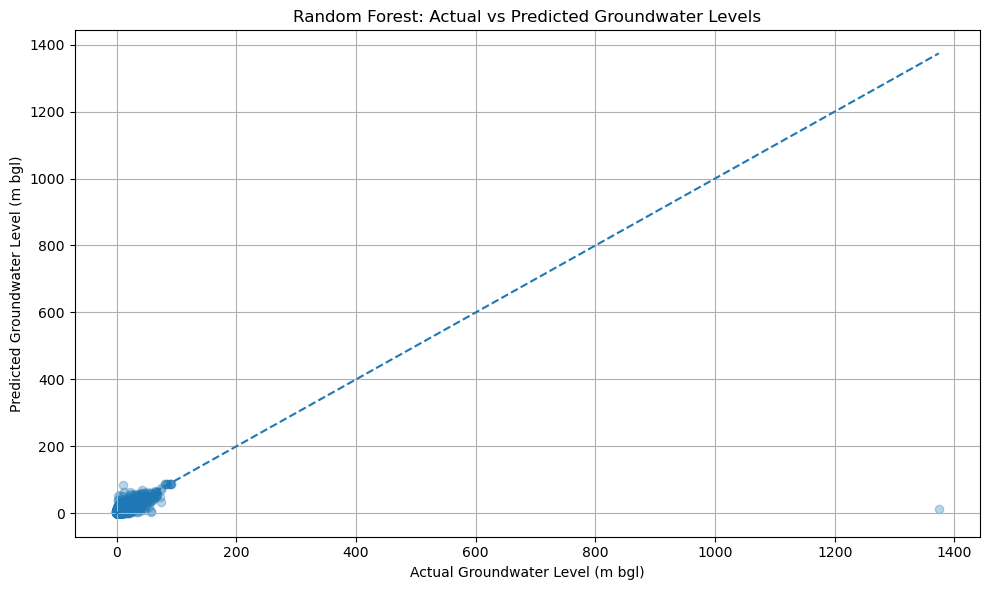

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    rf_prediction_series,
    alpha=0.3
)

minimum = min(y_test.min(), rf_prediction_series.min())
maximum = max(y_test.max(), rf_prediction_series.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Groundwater Level (m bgl)")
plt.ylabel("Predicted Groundwater Level (m bgl)")
plt.title("Random Forest: Actual vs Predicted Groundwater Levels")
plt.grid(True)
plt.tight_layout()
plt.show()

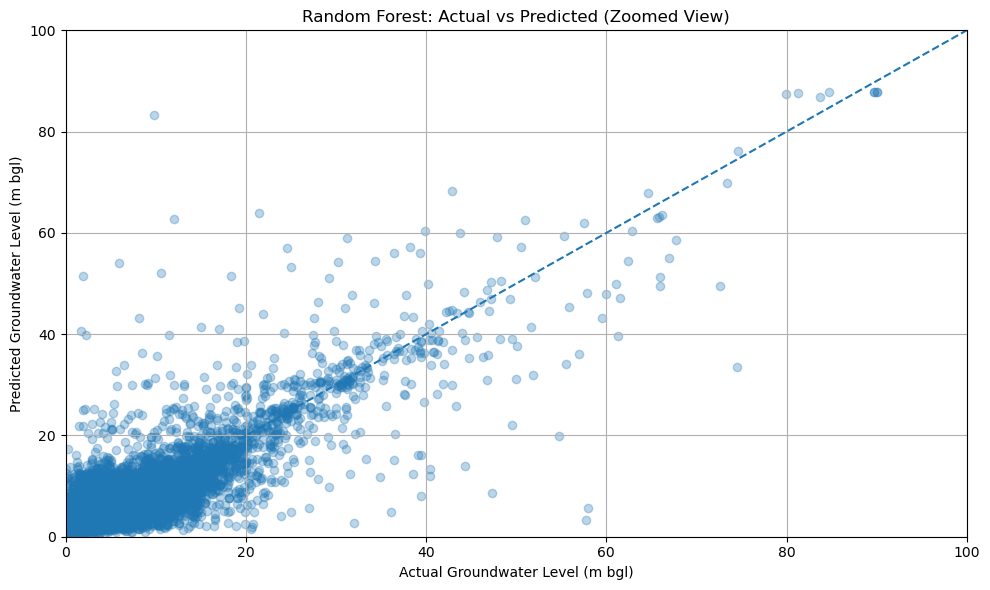

In [33]:
# Zoomed-in graph for readings between 0 and 100 m

normal_range = error_analysis[
    error_analysis["Actual"].between(0, 100)
]

plt.figure(figsize=(10, 6))

plt.scatter(
    normal_range["Actual"],
    normal_range["Predicted"],
    alpha=0.3
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.xlabel("Actual Groundwater Level (m bgl)")
plt.ylabel("Predicted Groundwater Level (m bgl)")
plt.title("Random Forest: Actual vs Predicted (Zoomed View)")
plt.grid(True)
plt.tight_layout()
plt.show()

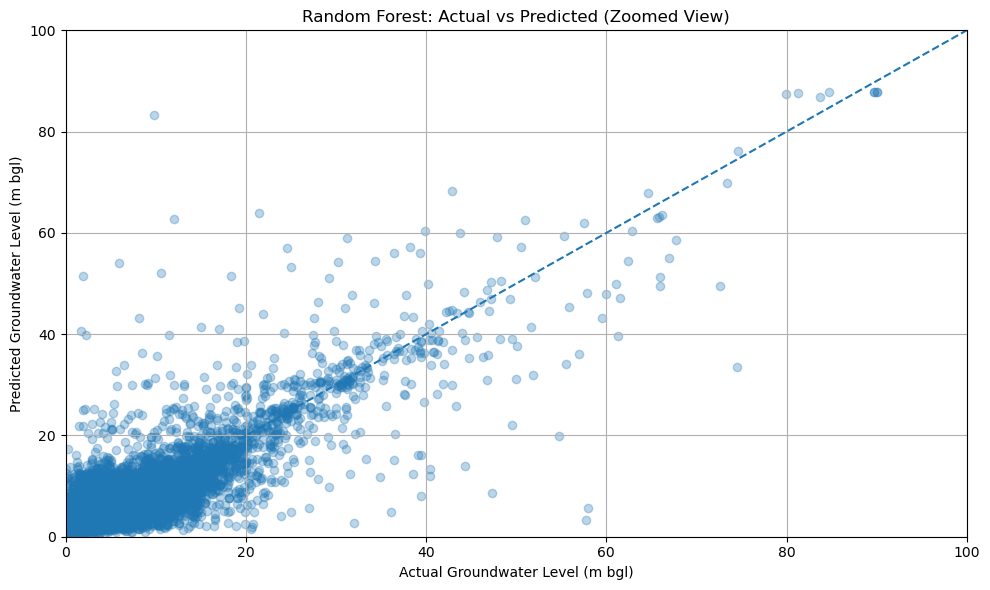

Graph saved successfully!
Location: D:\GroundWatch\reports\random_forest_actual_vs_predicted.png


In [34]:
# Save the zoomed-in evaluation graph

graph_path = reports_folder / "random_forest_actual_vs_predicted.png"

plt.figure(figsize=(10, 6))

plt.scatter(
    normal_range["Actual"],
    normal_range["Predicted"],
    alpha=0.3
)

plt.plot([0, 100], [0, 100], linestyle="--")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.xlabel("Actual Groundwater Level (m bgl)")
plt.ylabel("Predicted Groundwater Level (m bgl)")
plt.title("Random Forest: Actual vs Predicted (Zoomed View)")
plt.grid(True)
plt.tight_layout()

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved successfully!")
print("Location:", graph_path)

In [35]:
import joblib

# Save the trained Random Forest model

model_path = repo_root / "models" / "groundwater_predictor.pkl"

joblib.dump(random_forest_model, model_path)

print("Random Forest model saved successfully!")
print("Location:", model_path)

Random Forest model saved successfully!
Location: D:\GroundWatch\models\groundwater_predictor.pkl
